# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

### Выполнил: Московкин Александр Николаевич
### ИСУ: 472264
### Группа: J3312

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.** Укажите устройство, выбранную ветку, использованные внешние источники и нерешённые задачи (если есть).

**Сведения о сдаче.**

- Устройство: GPU NVIDIA T4 (Google Colab), PyTorch 2.11.0+cu130. Время основных обучений записано в `RUN_TIMES` и в `artifacts/metrics.json`.
- Финальный прогон: Restart & Run All с `FAST_MODE = False`.
- Ветка раздела 5: `ATTACK_TRACK = 'targeted'` (задача 5.2).
- Бонусы: `BONUS_TASKS = {'7.1', '7.2', '7.3', '7.4', '7.5'}`.
- Источники: документация PyTorch (`F.unfold`, `F.conv_transpose2d`, `torch.optim.AdamW`, `torch.optim.Muon` для сверки формул), статьи, на которые есть ссылки в условии. Код семинаров не копировал, кроме готовых функций из самого ноутбука.
- В `train_cifar` есть ветка `channels_last` только для CPU (ускоряет свёртки и не меняет математику), на GPU она не включается.
- `input_gradient` в 6.3 считает градиент по одному примеру, чтобы результат точно совпадал с отдельным вызовом `autograd.grad` из теста (при батче 1000 и батче 1 свёртки на GPU дают немного разные округления).
- Нерешённых задач нет.
- В раздел 1.3 добавлена одна вспомогательная ячейка `rf_support` (подсчёт числа пикселей с ненулевым градиентом), она нужна для ответа про MaxPool.

In [1]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0+cu130
CUDA available:  True
MPS available:   False


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

In [3]:
FAST_MODE = False # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted' # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = {'7.1', '7.2', '7.3', '7.4', '7.5'} # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [4]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [5]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [6]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # x: (B, C_in, H, W), weight: (C_out, C_in / groups, kh, kw) -> (B, C_out, H_out, W_out)
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape
    stride, padding, dilation = pair(stride), pair(padding), pair(dilation)
    assert C_in % groups == 0 and C_out % groups == 0
    H_out, W_out = conv_output_shape((H, W), (kh, kw), stride, padding, dilation)
    # cols: (B, C_in * kh * kw, L), строки упорядочены как (c, u, v), c самый внешний индекс
    cols = F.unfold(x, (kh, kw), dilation=dilation, padding=padding, stride=stride)
    # каналы группы g идут подряд, значит и их строки в cols идут одним блоком
    cols = cols.view(B, groups, (C_in // groups) * kh * kw, H_out * W_out)
    w = weight.reshape(groups, C_out // groups, (C_in // groups) * kh * kw)
    out = torch.matmul(w.unsqueeze(0), cols) # (B, groups, C_out / groups, L)
    out = out.reshape(B, C_out, H_out, W_out)
    if bias is not None:
        out = out + bias.view(1, -1, 1, 1)
    return out

In [7]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [8]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ.** По выводу ячейки `cols / x` = 9.0, 25.0 и 49.0 для k = 3, 5, 7, то есть ровно $k^2$. При `padding = k // 2` число позиций $L = HW$ не меняется, и каждый пиксель входа копируется в $k^2$ столбцов. Для батча 8x64x32x32 (2 MB во float32) это уже 18, 50 и 98 MB, а матричное умножение после im2col тоже стоит $O(C_{in} C_{out} k^2 HW)$. У FFT-свёртки ядро дополняется до размера картинки, поэтому стоимость (преобразования $O(C\,HW \log HW)$ плюс поэлементное произведение $O(C_{in} C_{out} HW)$) почти не зависит от $k$. Получается, что с ростом ядра im2col проигрывает квадратично и по памяти, и по операциям, а FFT нет, поэтому FFT выгодна именно на больших ядрах. На 3x3 накладные расходы FFT обычно больше, чем выигрыш.

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [9]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding
        H, W = x.shape[-2:]
        kh, kw = weight.shape[-2:]
        H_out, W_out = grad_out.shape[-2:]
        grad_x = grad_w = grad_b = None
        if ctx.needs_input_grad[0]:
            # M^T g: транспонированная свёртка, output_padding восстанавливает исходный размер
            op_h = H - ((H_out - 1) * s - 2 * p + kh)
            op_w = W - ((W_out - 1) * s - 2 * p + kw)
            grad_x = F.conv_transpose2d(grad_out, weight, stride=s, padding=p, output_padding=(op_h, op_w))
        if ctx.needs_input_grad[1]:
            cols = F.unfold(x, (kh, kw), padding=p, stride=s) # (B, C_in*kh*kw, L)
            grad_w = torch.einsum('bol,bkl->ok', grad_out.flatten(2), cols).view_as(weight)
        if ctx.needs_input_grad[2]:
            grad_b = grad_out.sum(dim=(0, 2, 3))
        return grad_x, grad_w, grad_b, None, None

In [10]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.** $H_{out} = \lfloor (H + 2 - 3)/2 \rfloor + 1$. Для $H = 7$ и $H = 8$ получаем одинаковый $H_{out} = 4$. Без `output_padding` транспонированная свёртка восстанавливает $(H_{out} - 1)s - 2p + k = 3 \cdot 2 - 2 + 3 = 7$ строк. Значит $\mathrm{op}_H = 7 - 7 = 0$ для $H = 7$ и $\mathrm{op}_H = 8 - 7 = 1$ для $H = 8$. Во втором случае последняя строка входа всё равно попадает в последнее окно, и её градиент считается честно, `output_padding` только сообщает, какой формы должен быть ответ. Аналогично работает пара $H = 9$ и $H = 10$ ($H_{out} = 5$, op = 0 и 1). `gradcheck` в тесте прошёл на всех 27 комбинациях, включая случаи с ненулевым op.

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [11]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [12]:
def empirical_rf(model, in_channels=1, size=96):
    # -> (высота, ширина) bounding box пикселей входа, влияющих на центральный выход
    x = torch.randn(1, in_channels, size, size, requires_grad=True)
    out = model(x)
    h, w = out.shape[-2:]
    grad, = torch.autograd.grad(out[0, :, h // 2, w // 2].sum(), x)
    support = grad[0].abs().sum(dim=0) != 0 # (size, size)
    rows = support.any(dim=1).nonzero().flatten()
    cols = support.any(dim=0).nonzero().flatten()
    if len(rows) == 0:
        return (0, 0)
    return (int(rows.max() - rows.min()) + 1, int(cols.max() - cols.min()) + 1)

In [13]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


In [14]:
# Дополнительная проверка к вопросу: bounding box может совпасть, поэтому считаем сам носитель градиента
def rf_support(model, size=96):
    x = torch.randn(1, 1, size, size, requires_grad=True)
    out = model(x)
    h, w = out.shape[-2:]
    grad, = torch.autograd.grad(out[0, :, h // 2, w // 2].sum(), x)
    return int((grad != 0).sum())


torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    print(f'{name:<12} r*r = {r * r:>4}   nonzero pixels: AvgPool {rf_support(make_avg_net(layers)):>4}, '
          f'MaxPool {rf_support(make_avg_net(layers, max_pool=True)):>4}')

conv3x3 x4   r*r =   81   nonzero pixels: AvgPool   81, MaxPool   81
conv-pool    r*r =  324   nonzero pixels: AvgPool  324, MaxPool  258
strided      r*r =  289   nonzero pixels: AvgPool  289, MaxPool  289
dilated      r*r =  225   nonzero pixels: AvgPool  225, MaxPool  225


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** Сеть из усредняющих свёрток и AvgPool линейна, и все её коэффициенты неотрицательны. Градиент центрального выхода по входу не зависит от входа и равен произведению матриц с неотрицательными элементами, поэтому нет ни обнуления от ReLU, ни взаимного сокращения слагаемых разного знака. Носитель градиента тогда совпадает ровно с теоретическим RF, и тест получается строгим: любое расхождение означает ошибку в коде. В нашем прогоне все четыре сети дали (r, r): 9, 18, 17, 15.

С MaxPool градиент проходит только в аргмакс каждого окна пулинга, поэтому он зависит от входа и становится разреженным. Bounding box в нашем прогоне не изменился (18x18 для conv-pool), но число ненулевых пикселей упало с 324 до 258 (доп. ячейка `rf_support`). Края всё ещё достаются, потому что перед пулингом стоит свёртка 3x3, которая "размазывает" выбранную позицию на соседей, и на случайном входе какой-то аргмакс попадает на край. В общем случае box с MaxPool не больше теоретического и на другом входе может оказаться меньше. Для сетей без пулинга ничего не меняется (81, 289, 225 пикселей).

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [15]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    # входы батча независимы (в сетях нет BN), поэтому градиент суммы даёт градиенты по каждому входу
    x = torch.randn(n_inputs, in_channels, size, size, requires_grad=True)
    out = model(x)
    h, w = out.shape[-2:]
    grad, = torch.autograd.grad(out[:, :, h // 2, w // 2].sum(), x)
    saliency = grad.abs().mean(dim=0).sum(dim=0).double() # (size, size)
    p = saliency.sum(dim=1) # распределение по строкам
    p = p / p.sum()
    idx = torch.arange(size, dtype=p.dtype)
    mu = (p * idx).sum()
    return (p * (idx - mu) ** 2).sum().sqrt().item()

In [16]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [17]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


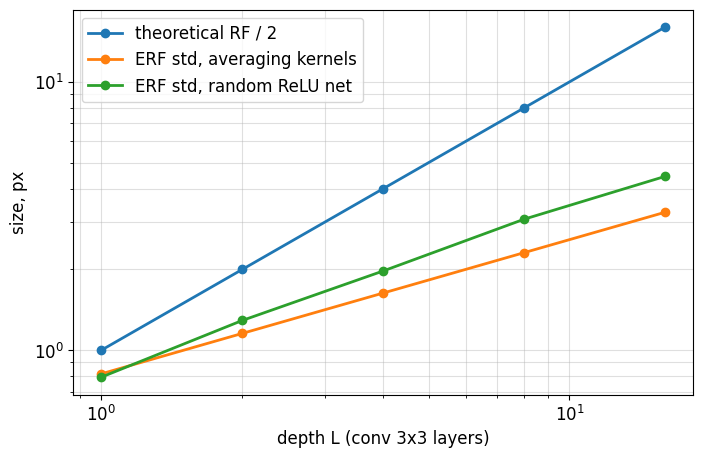

In [18]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.** Теоретический RF растёт линейно ($r_L/2 = L$, наклон 1 на log-log графике). ERF усредняющей сети: 0.82, 1.15, 1.63, 2.31, 3.27 для L = 1, 2, 4, 8, 16, это ровно $\sqrt{2L/3}$, наклон по МНК 0.50. Поэтому отношение эффективного размера к теоретическому падает как $1/\sqrt L$: $\sigma / (2L + 1)$ равно 0.27 при L = 1 и 0.10 при L = 16, то есть вклад в выход почти целиком даёт центральная часть RF, а края почти не влияют. Сеть с ReLU и случайными весами: 0.79, 1.29, 1.97, 3.08, 4.44, наклон около 0.62. Она растёт немного быстрее усредняющей (при L = 16 ERF шире в 1.36 раза), но всё равно заметно медленнее линейного: при L = 16 std 4.4 пикселя при теоретическом полуразмере 16. Это согласуется с Luo et al.: профиль близок к гауссовскому, и ERF занимает малую долю RF. В дополнение, хотел бы сказать, что ReLU-сеть усреднена всего по 16 входам и одной инициализации (seed 0), так что точное значение наклона 0.62 не стоит переоценивать.

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [19]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.num_features = num_features
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        shape = (1, -1, 1, 1)
        if self.training:
            n = x.numel() // x.shape[1]
            if n <= 1:
                raise ValueError('Expected more than 1 value per channel when training')
            mean = x.mean(dim=(0, 2, 3))
            var = ((x - mean.view(shape)) ** 2).mean(dim=(0, 2, 3)) # смещённая оценка
            with torch.no_grad():
                self.num_batches_tracked.add_(1)
                # momentum=None, как в nn.BatchNorm2d, означает кумулятивное среднее
                m = 1.0 / self.num_batches_tracked.item() if self.momentum is None else self.momentum
                self.running_mean.mul_(1 - m).add_(m * mean.detach())
                self.running_var.mul_(1 - m).add_(m * var.detach() * n / (n - 1))
        else:
            mean, var = self.running_mean, self.running_var
        x_hat = (x - mean.view(shape)) / torch.sqrt(var.view(shape) + self.eps)
        return x_hat * self.weight.view(shape) + self.bias.view(shape)

In [20]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.** В режиме обучения нам нужно нормировать именно этот батч, то есть сделать его среднее 0 и дисперсию 1. Для этого берётся фактический второй центральный момент батча, это смещённая оценка, и формулы backward BN тоже выведены для неё. Running-статистика нужна для другого: на инференсе она оценивает дисперсию по всей генеральной совокупности, а выборочная дисперсия по $n$ точкам в среднем занижена в $(n - 1)/n$ раз, поэтому туда пишется несмещённая оценка. Различие равно множителю $n/(n - 1)$. При $B = 4$ и карте 5x5 $n = 100$, множитель 1.0101, то есть около 1%. При $B = 2$ и карте $1$ x $1$ $n = 2$, множитель 2: смещённая оценка вдвое меньше несмещённой. Кроме того, при $n = 2$ нормированные значения в train всегда равны примерно $\pm 1$ независимо от данных, так что такой BN почти не несёт информации, а running-статистики очень шумные.

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.** В `eval()` BN для канала $o$ это $\mathrm{BN}(z)_o = \gamma_o \dfrac{z_o - \hat\mu_o}{\sqrt{\hat\sigma^2_o + \epsilon}} + \beta_o$. Обозначим $s_o = \gamma_o / \sqrt{\hat\sigma^2_o + \epsilon}$. Подставляем $z_o = (W * x)_o + b_o$:
$$
\mathrm{BN}(\mathrm{conv}(x))_o = s_o (W * x)_o + s_o (b_o - \hat\mu_o) + \beta_o = (W' * x)_o + b'_o,
$$
$$
W'[o, \cdot, \cdot, \cdot] = s_o\, W[o, \cdot, \cdot, \cdot], \qquad b'_o = s_o\,(b_o - \hat\mu_o) + \beta_o .
$$
Если у свёртки нет bias, то $b_o = 0$. Масштабирование идёт по выходному каналу, поэтому формула не зависит от groups, stride, padding и dilation, и они переносятся в новую свёртку без изменений.

In [21]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    w = conv.weight
    fused = nn.Conv2d(conv.in_channels, conv.out_channels, conv.kernel_size,
                      stride=conv.stride, padding=conv.padding, dilation=conv.dilation,
                      groups=conv.groups, bias=True, padding_mode=conv.padding_mode,
                      device=w.device, dtype=w.dtype)
    mean, var = bn.running_mean.to(w), bn.running_var.to(w)
    gamma, beta = bn.weight.to(w), bn.bias.to(w)
    scale = gamma / torch.sqrt(var + bn.eps) # (C_out,)
    b = conv.bias if conv.bias is not None else torch.zeros_like(mean)
    fused.weight.copy_(w * scale.view(-1, 1, 1, 1))
    fused.bias.copy_((b - mean) * scale + beta)
    fused.train(conv.training)
    return fused


def fuse_sequential(seq):
    items = list(seq.named_children())
    fused, i = [], 0
    while i < len(items):
        name, module = items[i]
        nxt = items[i + 1][1] if i + 1 < len(items) else None
        if isinstance(module, nn.Conv2d) and isinstance(nxt, nn.BatchNorm2d):
            fused.append((name, fuse_conv_bn(module, nxt)))
            i += 2
        else:
            fused.append((name, copy.deepcopy(module)))
            i += 1
    out = nn.Sequential()
    for name, module in fused:
        out.add_module(name, module)
    return out.train(seq.training)

In [22]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1)) # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [23]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32)) # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [24]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 136.2 ms   fused: 155.7 ms   speedup 0.87x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.** В `train()` BN нормирует статистиками текущего батча: $\mu$ и $\sigma^2$ зависят от всех примеров батча и меняются от шага к шагу, это не фиксированное поканальное аффинное преобразование, и запечь его в постоянные веса нельзя (плюс в train обновляются running-буферы). В `eval()` статистики заморожены, и BN становится обычной поканальной аффинной функцией, которая сливается со свёрткой точно. Слияние убирает отдельный проход по тензору активаций (чтение и запись карты признаков), лишний вызов ядра и параметры BN. Выигрыш зависит от того, во что упирается сеть: если свёртки тяжёлые и вычисления доминируют, доля BN мала, если сеть ограничена памятью или накладными расходами на запуск ядер (GPU, маленькие батчи, много тонких слоёв), выигрыш больше. В нашем прогоне эта ячейка считается на CPU (модель `vgg` не переносится на GPU), получилось 136.2 ms против 155.7 ms, то есть слитая сеть даже немного медленнее (0.87x). Выигрыша на CPU здесь нет: свёртка 3x3 с 64 каналами занимает почти всё время, а поэлементный BN дешёвый, и разброс замера на общем виртуальном CPU Colab (5 повторов по 5 запусков) больше, чем ожидаемый эффект от слияния. Так что этот замер не показывает ни выигрыша, ни реального проигрыша, а только то, что на CPU для такой сети эффект слияния в пределах шума.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.** Пусть $h^{prev}$ симметрична с дисперсией $q$. Для ReLU $\mathbb E[z_j^2] = \mathbb E[h^2 \mathbb 1_{h > 0}] = q/2$, поэтому $\mathrm{Var}(h_i) = n v q / 2$, и масштаб сохраняется при $v = 2/n$. Для tanh в линейном режиме $\tanh(h) \approx h$, $\mathbb E[z_j^2] \approx q$, и нужно $v = 1/n$ (это Xavier при fan_in = fan_out: $2/(n + n) = 1/n$). Инициализация `nn.Linear` по умолчанию $\mathcal U(-1/\sqrt n, 1/\sqrt n)$ имеет $v = \frac{(2/\sqrt n)^2}{12} = \frac{1}{3n}$. Для ReLU за слой дисперсия умножается на $n \cdot \frac{1}{3n} \cdot \frac12 = \frac16$, а стандартное отклонение на $1/\sqrt 6 \approx 0.408$, то есть уменьшается примерно в 2.45 раза за слой.

In [25]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    h = torch.randn(n, width)
    stds = []
    with torch.no_grad():
        for _ in range(depth):
            W = torch.empty(width, width) # как weight у nn.Linear: (out, in), fan_in = width
            init(W)
            h = act(h @ W.T)
            stds.append(h.std().item())
    return stds

In [26]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu)))) # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.758


np.float64(0.40910241812972786)

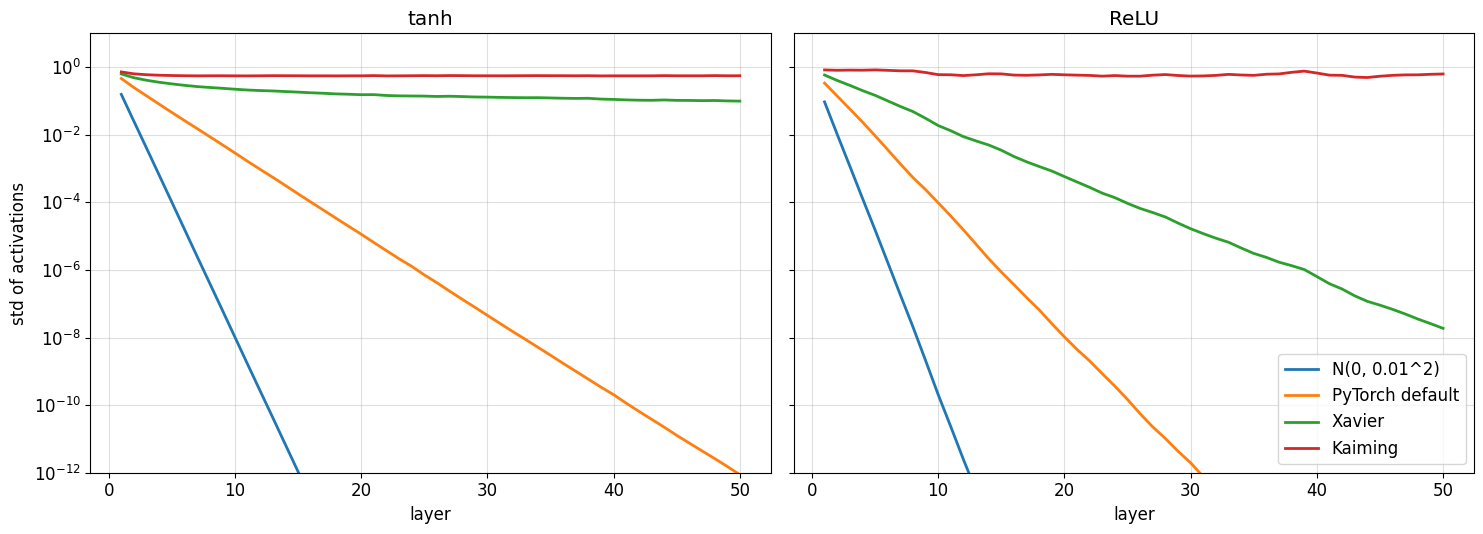

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** Масштаб на 50 слоях держат Kaiming + ReLU (std 0.83 на первом слое и 0.63 на последнем, средний множитель за слой 0.994) и Kaiming + tanh (0.72 и 0.56, множитель 0.995, tanh здесь частично насыщается, и это насыщение уравновешивает слишком большую для tanh дисперсию $2/n$). Xavier + tanh почти держит: 0.63 и 0.099, множитель 0.963, затухание медленное, потому что tanh сжимает сигнал сильнее линейного режима. Остальные пары затухают экспоненциально: Xavier + ReLU с множителем 0.70 (это $1/\sqrt 2$ из вывода выше) до 2e-8, PyTorch default + ReLU с множителем 0.409 (тест сверил с $1/\sqrt 6$) до 3e-20, default + tanh 0.58 до 9e-13, $\mathcal N(0, 0.01^2)$ с множителем 0.16 до 1e-40 для tanh и до точного нуля (underflow float32) для ReLU.

Сети с инициализацией по умолчанию всё равно обучаются, потому что в ResNet из 4.2 после каждой свёртки стоит BatchNorm: он заново нормирует каждый канал к единичной дисперсии, и выход BN не зависит от масштаба весов свёртки. Кроме того, residual-связи дают путь, где сигнал и градиент не проходят через произведение десятков матриц, а Adam нормирует шаг по величине градиента, так что маленький масштаб градиентов не мешает. В MLP из этого опыта нет ни нормализации, ни skip-связей, поэтому там затухание ничем не компенсируется.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [28]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                lr, eps, wd = group['lr'], group['eps'], group['weight_decay']
                g = p.grad
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p, memory_format=torch.preserve_format)
                    state['exp_avg_sq'] = torch.zeros_like(p, memory_format=torch.preserve_format)
                state['step'] += 1
                t = state['step']
                m, v = state['exp_avg'], state['exp_avg_sq']
                p.mul_(1 - lr * wd) # decoupled weight decay
                m.mul_(beta1).add_(g, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(g, g, value=1 - beta2)
                if group['bias_correction']:
                    bc1, bc2 = 1 - beta1 ** t, 1 - beta2 ** t
                else:
                    bc1, bc2 = 1.0, 1.0
                denom = (v / bc2).sqrt_().add_(eps)
                p.addcdiv_(m, denom, value=-lr / bc1)

In [29]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [30]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


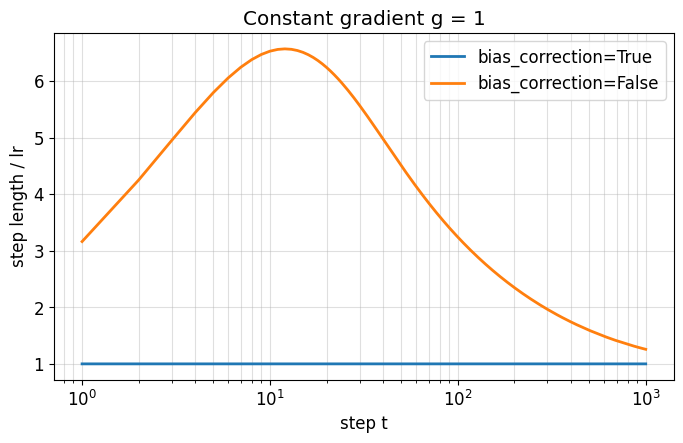

In [31]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.** Без bias correction при $g_t \equiv 1$: $m_t = (1 - \beta_1)\sum_{i<t}\beta_1^i = 1 - \beta_1^t$, аналогично $v_t = 1 - \beta_2^t$, и шаг
$$
\Delta_t = \eta\, \frac{1 - \beta_1^t}{\sqrt{1 - \beta_2^t} + \epsilon} \approx \eta\, \frac{1 - 0.9^t}{\sqrt{1 - 0.999^t}} .
$$
При $t = 1$ это $0.1/\sqrt{0.001} = 3.16\eta$, при $t = 10$: $0.651/0.0998 = 6.53\eta$, при $t = 100$: $3.24\eta$, при $t = 1000$: $1/\sqrt{0.632} = 1.26\eta$, и только при $t \to \infty$ стремится к $\eta$. Это совпадает с выводом ячейки (3.16, 6.53, 3.24, 1.26, максимум 6.57 при t = 12). С bias correction шаг ровно $\eta$ с первого шага. Опасность в том, что $v_t$ (с $\beta_2 = 0.999$) "разгоняется" намного медленнее, чем $m_t$, поэтому первые сотни шагов эффективный learning rate в 3-6.6 раз больше номинального. Это происходит в начале обучения, когда веса случайные, градиенты большие и быстро меняются, и такой скачок может дать всплески loss, развал BN-статистик или полную расходимость. По сути это анти-warmup: шаг больше всего там, где его нужно делать меньше всего.

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [32]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    progress = min(1.0, max(0, step) / total_steps) if total_steps > 0 else 1.0
    return min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * progress)) / 2

In [33]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

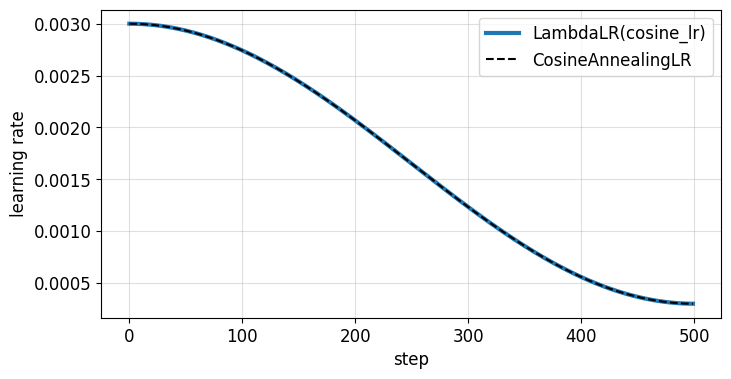

In [34]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** Адаптивность Adam нормирует шаг на масштаб градиента $\sqrt{\hat v}$, но не на его "полезную" часть. Около минимума средний градиент мал, а шум мини-батчей остаётся, и $\hat m / \sqrt{\hat v}$ по координате остаётся порядка единицы, так что длина шага сама по себе не уменьшается и всё ещё порядка $\eta$. Стохастический метод с постоянным шагом около минимума не сходится к точке: итерации колеблются в окрестности минимума, размер которой растёт с шагом (для SGD стационарная дисперсия пропорциональна $\eta \sigma^2$), и loss держится на уровне "шумового пола". Уменьшение learning rate к концу сжимает эту окрестность и опускает loss. Cosine schedule даёт большой шаг в начале (быстрый прогресс и исследование) и плавно уменьшает его к концу. Это видно в 4.2: train loss упал с 0.27 на 10-й эпохе до 0.012 на 20-й, при этом test accuracy выросла с 0.801 до 0.831.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [35]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous() # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

100%|██████████| 170M/170M [02:29<00:00, 1.14MB/s]


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='cuda:0'),
 tensor([0.2470, 0.2435, 0.2616], device='cuda:0'))

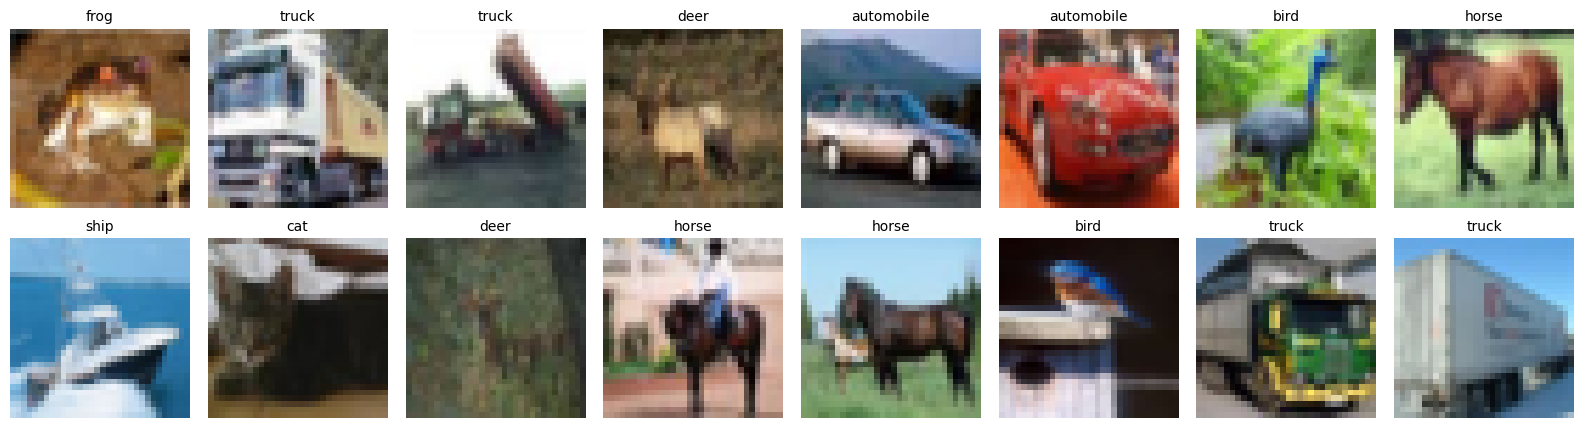

In [36]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [37]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if not separable:
        return nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)
    return nn.Sequential(
        nn.Conv2d(c_in, c_in, 3, stride=stride, padding=1, groups=c_in, bias=False), # depthwise
        nn.Conv2d(c_in, c_out, 1, bias=False), # pointwise
    )


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.conv1 = conv3x3(c_in, c_out, stride, separable)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = conv3x3(c_out, c_out, 1, separable)
        self.bn2 = nn.BatchNorm2d(c_out)
        if residual:
            if stride != 1 or c_in != c_out:
                self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                                              nn.BatchNorm2d(c_out))
            else:
                self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
                                  nn.BatchNorm2d(widths[0]), nn.ReLU())
        blocks, c = [], widths[0]
        for stage, width in enumerate(widths):
            for i in range(n):
                stride = 2 if stage > 0 and i == 0 else 1
                blocks.append(Block(c, width, stride, residual, separable))
                c = width
        self.blocks = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c, n_classes)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(self.pool(x).flatten(1))

In [38]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [39]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()
    # channels_last ускоряет свёртки на CPU (oneDNN) примерно на 25%, на результат не влияет
    channels_last = device.type == 'cpu'
    if channels_last:
        model = model.to(memory_format=torch.channels_last)

    def transform(x):
        x = normalize(x)
        return x.contiguous(memory_format=torch.channels_last) if channels_last else x

    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    optimizer = MyAdamW([dict(params=decay, weight_decay=weight_decay),
                         dict(params=no_decay, weight_decay=0.0)], lr=lr)
    total_steps = epochs * math.ceil(len(X_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda t: cosine_lr(t, total_steps, 0.0))
    for epoch in range(epochs):
        model.train()
        loss_sum, n_seen = 0.0, 0
        for x, y in iterate_batches(X_train, Y_train, batch_size, shuffle=True, transform=transform):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            scheduler.step()
            loss_sum += loss.item() * len(y)
            n_seen += len(y)
        history['train_loss'].append(loss_sum / n_seen)
        history['test_acc'].append(accuracy(predict_logits(model, X_test, transform=transform), Y_test))
        if log:
            print(f'epoch {epoch + 1:>2}/{epochs}  train loss {history["train_loss"][-1]:.4f}  '
                  f'test acc {history["test_acc"][-1]:.4f}  lr {scheduler.get_last_lr()[0]:.2e}  '
                  f'{(time.time() - start) / 60:.1f} min')
    model.eval()
    return history

In [40]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

epoch  1/20  train loss 1.4267  test acc 0.5235  lr 2.98e-03  0.3 min
epoch  2/20  train loss 0.9629  test acc 0.5638  lr 2.93e-03  0.6 min
epoch  3/20  train loss 0.7724  test acc 0.6554  lr 2.84e-03  0.8 min
epoch  4/20  train loss 0.6539  test acc 0.7287  lr 2.71e-03  1.1 min
epoch  5/20  train loss 0.5741  test acc 0.7269  lr 2.56e-03  1.4 min
epoch  6/20  train loss 0.5011  test acc 0.7632  lr 2.38e-03  1.6 min
epoch  7/20  train loss 0.4361  test acc 0.7335  lr 2.18e-03  1.9 min
epoch  8/20  train loss 0.3769  test acc 0.7620  lr 1.96e-03  2.2 min
epoch  9/20  train loss 0.3254  test acc 0.8098  lr 1.73e-03  2.5 min
epoch 10/20  train loss 0.2710  test acc 0.8013  lr 1.50e-03  2.8 min
epoch 11/20  train loss 0.2170  test acc 0.8054  lr 1.27e-03  3.0 min
epoch 12/20  train loss 0.1617  test acc 0.8093  lr 1.04e-03  3.3 min
epoch 13/20  train loss 0.1148  test acc 0.8225  lr 8.19e-04  3.6 min
epoch 14/20  train loss 0.0719  test acc 0.8227  lr 6.18e-04  3.9 min
epoch 15/20  train l

{'train acc': 0.9997999668121338, 'test acc': 0.8312000036239624}

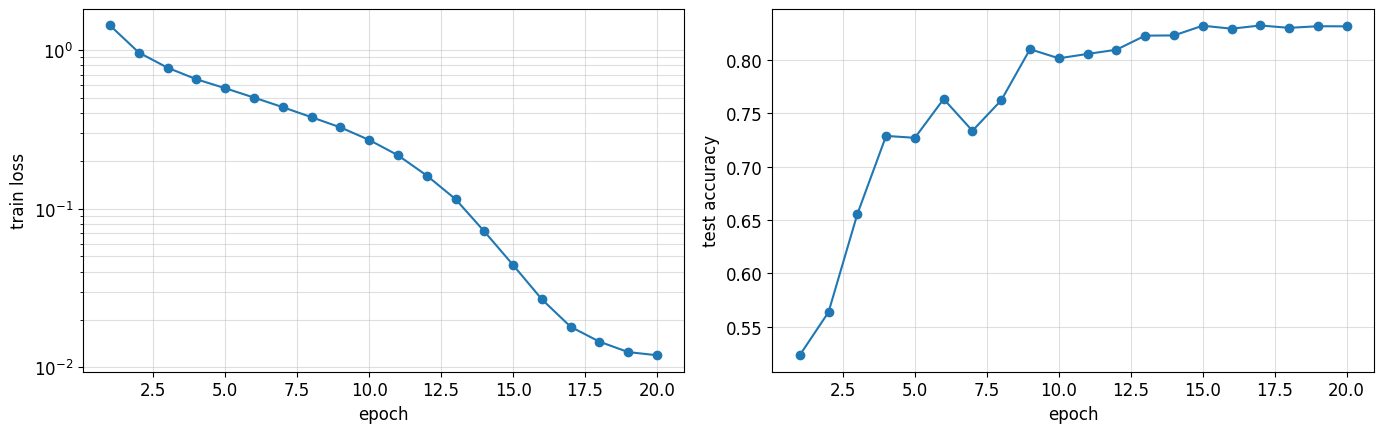

In [41]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** В конце обучения train accuracy (на первых 10 000 объектах train) 0.9998, test accuracy 0.831, разрыв около 17 п.п. Ориентир 0.82 достигнут. На последних эпохах, когда learning rate по косинусу уходит к нулю, train loss продолжает быстро падать: 0.044 на 15-й эпохе, 0.018 на 17-й, 0.012 на 20-й, то есть ещё примерно в 3.7 раза. Test accuracy при этом почти стоит: 0.8318, 0.8290, 0.8320, 0.8298, 0.8313, 0.8312, колебания в пределах 0.003, что меньше шума на 10 000 примерах. Основной прирост test accuracy пришёлся на середину спада lr (0.801 на 10-й эпохе и 0.823 на 14-й). Модель фактически запоминает train: аугментаций нет, 272 тыс. параметров на 50 тыс. картинок, и маленький шаг в конце уводит её в узкий минимум train loss, который на тест уже почти не переносится. Ухудшения test accuracy в конце при этом тоже нет. Вывод сделан по одному seed и одному прогону.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [42]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [43]:
ablation = {}
for name, cfg in ABLATIONS.items():
    set_seed(0)
    model = ResNetCIFAR(**cfg)
    print(name)
    started = time.perf_counter()
    hist = train_cifar(model, ABL_EPOCHS, LR)
    seconds = time.perf_counter() - started
    RUN_TIMES[f'cifar_{name}_seconds'] = seconds
    train_acc_abl = accuracy(predict_logits(model, X_train[:10_000], transform=normalize), Y_train[:10_000])
    ablation[name] = dict(params=n_params(model), train_acc=train_acc_abl, test_acc=hist['test_acc'][-1],
                          minutes=seconds / 60, history=hist)

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

plain-20
epoch  1/10  train loss 1.7151  test acc 0.2940  lr 2.93e-03  0.3 min
epoch  2/10  train loss 1.3639  test acc 0.4485  lr 2.71e-03  0.6 min
epoch  3/10  train loss 1.1048  test acc 0.6196  lr 2.38e-03  0.8 min
epoch  4/10  train loss 0.9307  test acc 0.6544  lr 1.96e-03  1.1 min
epoch  5/10  train loss 0.7982  test acc 0.6960  lr 1.50e-03  1.4 min
epoch  6/10  train loss 0.6900  test acc 0.7201  lr 1.04e-03  1.7 min
epoch  7/10  train loss 0.5965  test acc 0.7649  lr 6.18e-04  2.0 min
epoch  8/10  train loss 0.5246  test acc 0.7826  lr 2.86e-04  2.2 min
epoch  9/10  train loss 0.4682  test acc 0.7859  lr 7.34e-05  2.5 min
epoch 10/10  train loss 0.4402  test acc 0.7879  lr 0.00e+00  2.8 min
plain-56
epoch  1/10  train loss 1.9688  test acc 0.2283  lr 2.93e-03  0.8 min
epoch  2/10  train loss 1.7984  test acc 0.2290  lr 2.71e-03  1.7 min
epoch  3/10  train loss 1.7100  test acc 0.2744  lr 2.38e-03  2.5 min
epoch  4/10  train loss 1.6250  test acc 0.3503  lr 1.96e-03  3.4 min
ep

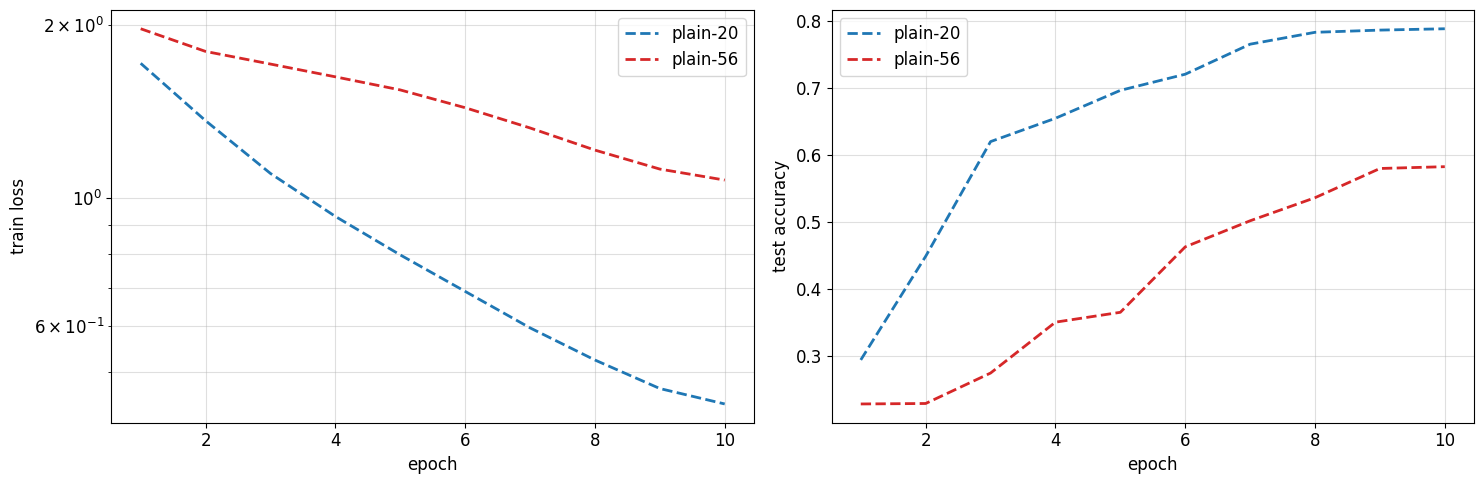

In [44]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** Да, ухудшение на train есть. При одинаковом протоколе (10 эпох, LR = 0.003, seed 0) plain-20 закончил с train loss 0.440, train accuracy 0.856 и test accuracy 0.788, а plain-56 с train loss 1.076, train accuracy 0.619 и test accuracy 0.582. Глубокая сеть хуже уже на обучающей выборке, причём на каждой эпохе: после первой эпохи loss 1.97 против 1.72, и разрыв не сокращается к концу.

На трудности оптимизации указывает именно это: train loss и train accuracy у plain-56 намного хуже, хотя параметров у неё в 3.2 раза больше (853 тыс. против 270 тыс.), то есть не хватает не ёмкости, а способности оптимизатора её использовать. Переобучения у plain-56 нет: train и test близки (0.619 и 0.582, разрыв 3.7 п.п.). Признаки начинающегося переобучения скорее у plain-20 (разрыв 6.8 п.п.), но и она за 10 эпох ещё не дообучилась. То есть это случай "хуже на train", а не "лучше на train, хуже на test". Ограничения: бюджет короткий, и plain-56 могла бы догнать при более долгом обучении; один seed.

Контрольный эксперимент: обучить ResNet-56 (`residual=True`) по тому же протоколу (10 эпох, LR, `set_seed(0)`). Если ResNet-56 по train loss окажется не хуже plain-20, а plain-56 сильно хуже, значит проблема в оптимизации глубокой сети без shortcut, а не в глубине или числе параметров самих по себе.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [45]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 211kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.94MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.6MB/s]


(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [46]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [47]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [48]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.919, 'FGSM, eps=0.1': 0.072, 'PGD-20, eps=0.1': 0.008}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [49]:
def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    view = (-1,) + (1,) * (x.ndim - 1)
    x_adv = x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        g_norm = grad.flatten(1).norm(dim=1).clamp_min(1e-12).view(view)
        x_adv = x_adv.detach() + alpha * grad / g_norm
        delta = x_adv - x
        d_norm = delta.flatten(1).norm(dim=1).view(view)
        factor = torch.clamp(eps / d_norm.clamp_min(1e-12), max=1.0) # проекция на L2-шар
        x_adv = (x + delta * factor).clamp(0, 1)
    return x_adv.detach()

In [50]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.922; маленькое падение требует диагностики.


(0.922, 0.0)

In [51]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.919, 0.5: 0.436, 1.0: 0.08, 1.5: 0.012, 2.0: 0.0, 3.0: 0.0, 4.0: 0.0},
 0.006)

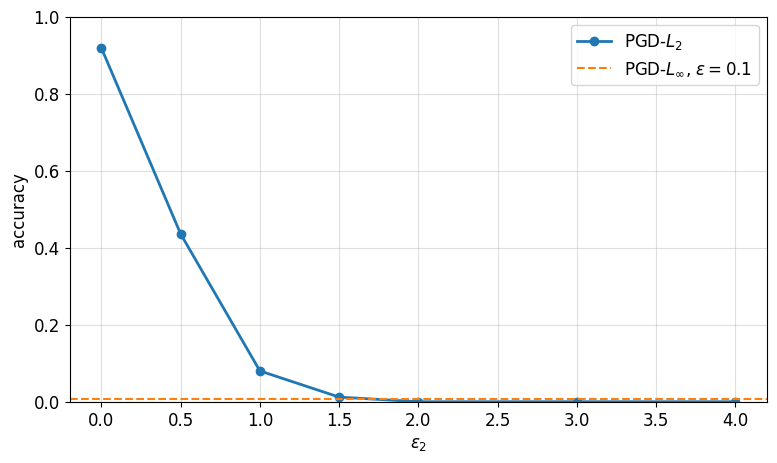

In [52]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=1.5, accuracy gap=0.006


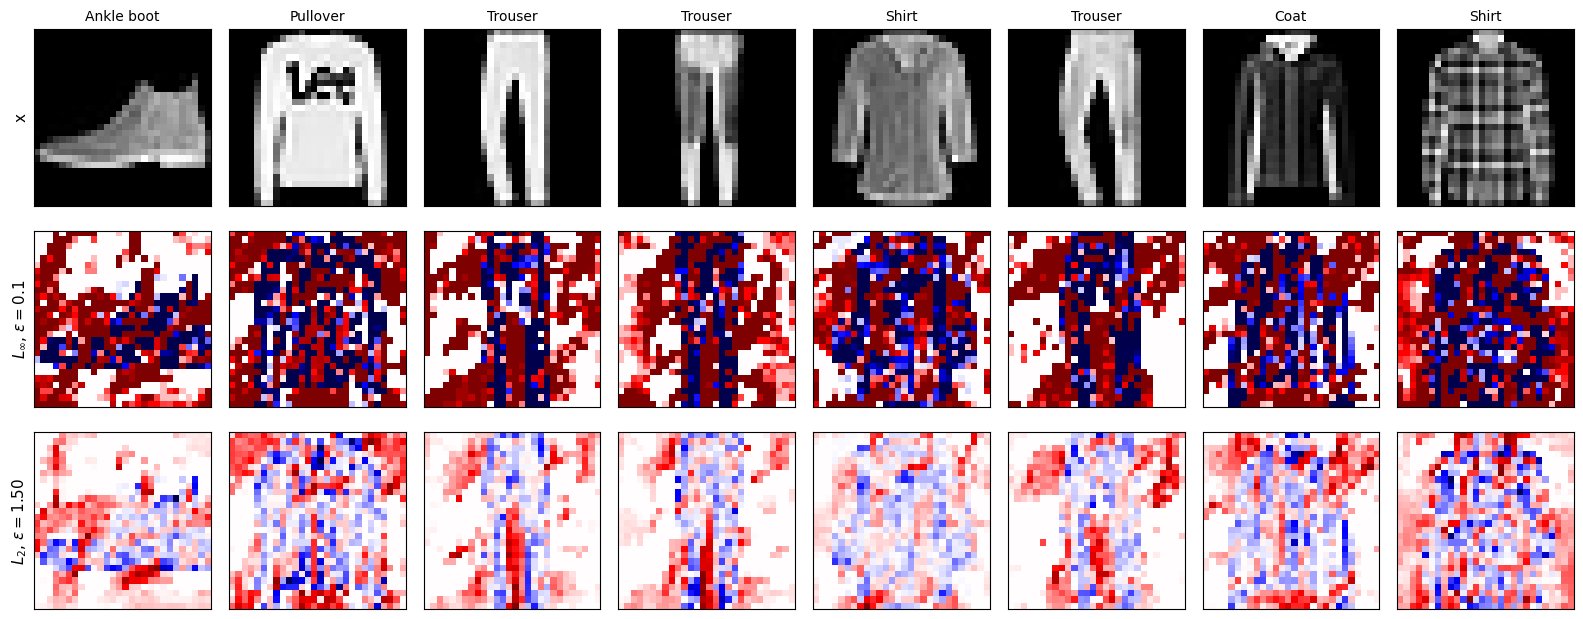

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.123
$L_2$, $\varepsilon=1.50$    L_inf = 0.249   L_2 = 1.492


In [53]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** Ближайшая точка сетки $\varepsilon_2 = 1.5$: accuracy 0.012 против 0.006 у $L_\infty$-атаки с $\varepsilon = 0.1$, остаточный разрыв 0.006. При $\varepsilon_2 = 2.0$ accuracy 0.000, и разрыв тоже 0.006, то есть две соседние точки сетки одинаково близки (код берёт первую). Обе атаки уже в насыщении, поэтому "равная сила" лежит где-то между 1.5 и 2.0, а точнее по этой сетке не определить, и сравнение карт ниже идёт не при строго равной силе атаки. $L_2$-норма самого $L_\infty$-возмущения в среднем по 8 картинкам 2.123, то есть больше и 1.5, и 2. Максимум был бы $0.1\sqrt{784} = 2.8$, норма меньше, потому что на чёрном фоне ($x = 0$) шаг вниз обрезается клипом, и там остаются только положительные изменения. Обратно, у $L_2$-возмущения с $\varepsilon_2 = 1.5$ $L_\infty$-норма 0.249, в 2.5 раза больше 0.1.

На картинках $L_\infty$-возмущение плотное: почти каждый пиксель сдвинут на $\pm 0.1$, включая весь фон. $L_2$-возмущение сосредоточено в отдельных местах: на контурах силуэта, в промежутке между штанинами у брюк (там красная полоса, которая "склеивает" ноги), на воротнике и рукавах, а большая часть фона почти не тронута. Это следует из формы шага: $g/\|g\|_2$ распределяет бюджет пропорционально $|g_i|$, поэтому пиксели с большим градиентом получают большую часть изменения, а пиксели с маленьким почти ничего. В $L_\infty$-атаке шаг $\mathrm{sign}(g)$ даёт всем пикселям одинаковую амплитуду независимо от величины градиента.

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [54]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        x = x.detach()
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
        for _ in range(steps):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), target), x_adv)
            x_adv = x_adv.detach() - alpha * grad.sign() # спуск по loss целевого класса
            x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
        return x_adv.detach()


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        model.eval()
        counts = torch.bincount(y.cpu(), minlength=n_classes).double()
        hits = torch.zeros(n_classes, n_classes, dtype=torch.float64)
        for t in range(n_classes):
            for i in range(0, len(x), 128):
                xb, yb = x[i:i + 128], y[i:i + 128]
                keep = yb != t
                if not keep.any():
                    continue
                xb, yb = xb[keep], yb[keep]
                target = torch.full_like(yb, t)
                x_adv = pgd_targeted(model, xb, target, eps, alpha=2.5 * eps / steps, steps=steps)
                with torch.no_grad():
                    hit = model(x_adv).argmax(dim=1) == target
                hits[:, t] += torch.bincount(yb[hit].cpu(), minlength=n_classes).double()
        S = torch.full((n_classes, n_classes), float('nan'), dtype=torch.float64)
        present = counts > 0
        S[present] = hits[present] / counts[present, None]
        S.fill_diagonal_(float('nan'))
        return S.float()

In [55]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.763; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.93 0.   0.01 0.03 0.   0.   0.04 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.04 0.   0.86 0.01 0.05 0.   0.05 0.   0.   0.  ]
 [0.05 0.   0.01 0.88 0.03 0.   0.02 0.   0.   0.  ]
 [0.   0.   0.05 0.03 0.9  0.   0.03 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.98 0.   0.01 0.   0.01]
 [0.09 0.   0.06 0.03 0.06 0.   0.75 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.   0.   0.   0.   0.   0.   0.01 0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]


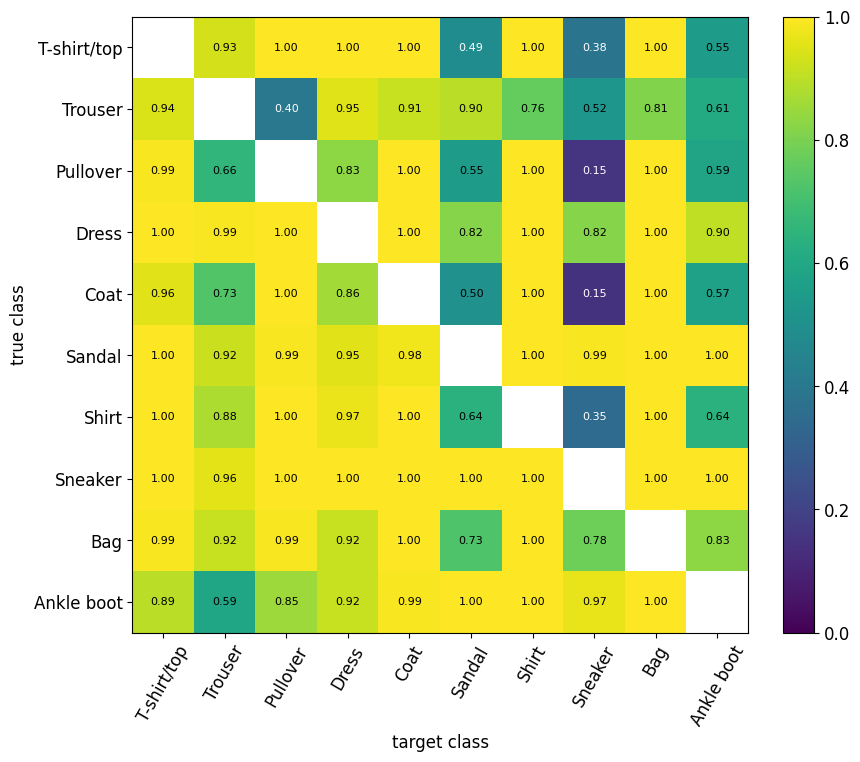

In [56]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** Сначала про тест: при цели $t = y + 1$ доля попаданий 0.763, хотя без атаки модель относит картинку к классу $y + 1$ меньше чем в 1% случаев (по clean confusion эти клетки почти все нулевые). Атака с $\varepsilon = 0.1$ в большинстве случаев навязывает нужный класс.

Легче всего атакуются цели Coat, Bag, T-shirt/top и Shirt (среднее по столбцу 0.99, 0.98, 0.98 и 0.97), из многих классов успех ровно 1.00. Самая трудная цель Sneaker (среднее по столбцу 0.57): Pullover → Sneaker 0.15, Coat → Sneaker 0.15, Shirt → Sneaker 0.35, T-shirt → Sneaker 0.38. Трудные также цели Sandal и Ankle boot (0.74): T-shirt → Sandal 0.49, Coat → Sandal 0.50. Плохо получается и Trouser → Pullover (0.40), Ankle boot → Trouser (0.59). По строкам хуже всего ломаются Pullover, Coat и Trouser (средний успех 0.75-0.76), легче всего Sneaker и Sandal (0.99 и 0.98).

Матрица заметно несимметрична, среднее $|S - S^\top|$ около 0.20. Например, Sneaker → Coat 1.00, а Coat → Sneaker 0.15; Sneaker → Pullover 1.00, а Pullover → Sneaker 0.15; Sneaker → T-shirt 1.00, а T-shirt → Sneaker 0.38. Объяснение, на мой взгляд, в том, что для перехода в Sneaker нужно "стереть" крупный светлый силуэт одежды и нарисовать низкий тёмный силуэт кроссовка, а в рамках $\pm 0.1$ на пиксель это почти невозможно. Обратно же достаточно добавить слабый узор, и модель уже видит "одежду".

Связь с clean confusion: пары, которые модель путает и без атаки, атакуются почти со 100% успехом: Shirt → T-shirt (clean 0.09, атака 1.00), Pullover → Coat и Coat → Pullover (0.05 и 1.00), Shirt → Pullover и Shirt → Coat (0.06 и 1.00), Pullover → Shirt (0.05 и 1.00), Ankle boot → Sneaker (0.04 и 0.97). Обратное неверно: много пар с нулевой clean-путаницей тоже дают 1.00 (например, Dress → Bag), потому что при $\varepsilon = 0.1$ атака сильная и успех насыщается. Поэтому clean confusion хорошо предсказывает лёгкие пары, а трудные пары лучше объясняются тем, насколько далеко целевой класс по форме. В строке около 100 картинок, так что различия меньше 0.05-0.1 лежат в пределах шума.

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [57]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.**

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [58]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [59]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    X_eval, Y_eval = XF_test[:1000], YF_test[:1000]
    start = time.time()
    for epoch in range(epochs):
        for x, y in iterate_batches(XF_train, YF_train, 128):
            model.eval() # атака строится в eval()
            x_adv = attack(model, x, y, eps).detach()
            model.train()
            loss = F.cross_entropy(model(x_adv), y) # только adversarial-примеры
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        model.eval()
        history['clean'].append(attack_accuracy(model, X_eval, Y_eval))
        history['fgsm'].append(attack_accuracy(model, X_eval, Y_eval, fgsm_attack, eps=eps))
        history['pgd'].append(attack_accuracy(model, X_eval, Y_eval, pgd, eps=eps))
        if log:
            print(f'epoch {epoch + 1}/{epochs}  clean {history["clean"][-1]:.3f}  FGSM {history["fgsm"][-1]:.3f}  '
                  f'PGD-20 {history["pgd"][-1]:.3f}  {(time.time() - start) / 60:.1f} min')
    model.eval()
    model.zero_grad(set_to_none=True)
    return history

In [60]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
epoch 1/5  clean 0.805  FGSM 0.697  PGD-20 0.666  0.2 min
epoch 2/5  clean 0.823  FGSM 0.702  PGD-20 0.660  0.3 min
epoch 3/5  clean 0.822  FGSM 0.725  PGD-20 0.698  0.5 min
epoch 4/5  clean 0.831  FGSM 0.718  PGD-20 0.696  0.6 min
epoch 5/5  clean 0.841  FGSM 0.741  PGD-20 0.717  0.8 min


In [61]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.919   0.126   0.005   0.000   0.000   0.000
PGD-AT       0.841   0.790   0.717   0.472   0.144   0.001


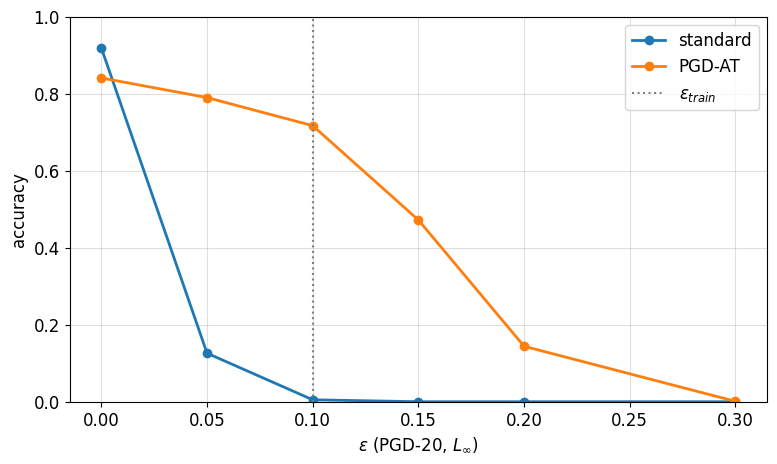

In [62]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.** Clean accuracy падает с 0.919 у обычной модели до 0.841 у PGD-AT, то есть робастность стоит около 8 п.п. Взамен PGD-20 accuracy при $\varepsilon = 0.1$ выросла с 0.005 до 0.717 (при $\varepsilon = 0.05$: 0.126 против 0.790). При $\varepsilon > \varepsilon_{train}$ робастность быстро исчезает: 0.472 при 0.15, 0.144 при 0.2 и 0.001 при 0.3. Модель защищена в основном внутри того шара, на котором обучалась, и гарантий за его пределами обучение не даёт, хотя небольшой запас шире $\varepsilon_{train}$ есть. У обычной модели всё почти нулевое уже с 0.1.

По числу проходов: на каждом батче PGD-7 делает 7 forward+backward по входу, плюс 1 forward+backward для шага по весам, всего 8 против 1 у обычного обучения, то есть примерно в 8 раз дороже. По замеру (`RUN_TIMES`) PGD-AT занял 47.2 с против 7.7 с у обычного обучения, отношение 6.1. Меньше 8 оно потому, что на GPU с такой маленькой моделью заметную долю времени занимают накладные расходы, которые не растут пропорционально числу проходов (при этом в 47.2 с входит ещё оценка после каждой эпохи).

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [63]:
def sanity_checks(model, x, y, eps):
    model.eval()
    correct = dict(fgsm=0, pgd20=0, pgd100_x5=0, eps_1=0)
    for i in range(0, len(x), 128):
        xb, yb = x[i:i + 128], y[i:i + 128]
        with torch.no_grad():
            clean_ok = model(xb).argmax(dim=1) == yb

        def still_correct(x_adv):
            with torch.no_grad():
                return (model(x_adv).argmax(dim=1) == yb) & clean_ok # clean-ошибка остаётся ошибкой

        correct['fgsm'] += still_correct(fgsm_attack(model, xb, yb, eps)).sum().item()
        correct['pgd20'] += still_correct(pgd(model, xb, yb, eps, steps=20)).sum().item()
        robust = clean_ok.clone()
        for _ in range(5):
            robust &= still_correct(pgd(model, xb, yb, eps, steps=100))
        correct['pgd100_x5'] += robust.sum().item()
        correct['eps_1'] += still_correct(pgd(model, xb, yb, 1.0, steps=20)).sum().item()
    return {k: v / len(x) for k, v in correct.items()}

In [64]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.074      0.016      0.008      0.000
PGD-AT                      0.746      0.719      0.715      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** Для PGD-AT accuracy монотонно уменьшается при усилении атаки: FGSM 0.746, PGD-20 0.719, PGD-100 с 5 рестартами 0.715, PGD-20 с $\varepsilon = 1$ ровно 0. От FGSM до самой сильной атаки падение 3.1 п.п., а от PGD-20 до PGD-100x5 только 0.4 п.п. (1 картинка из 256), то есть атака практически сошлась. Для обычной модели: 0.074, 0.016, 0.008, 0.000. Подозрительного я не вижу: более сильная атака не даёт более высокой accuracy, при $\varepsilon = 1$ атака доходит до нуля (градиенты не "сломаны" полностью), кривая accuracy от $\varepsilon$ в 6.1 монотонная, а результат PGD-AT по 256 объектам (0.719) близок к результату на 1000 объектах (0.717). Дополнительно я бы проверил атаки, которые не используют градиент модели напрямую: transfer с обычной модели, Square Attack или AutoAttack (APGD-CE и APGD-DLR), а также рост loss по шагам PGD и другие размеры шага.

Да, модель с высокой FGSM accuracy и почти нулевой PGD accuracy может пройти все перечисленные проверки: FGSM > PGD-20 ≥ PGD-100x5 монотонно, а при $\varepsilon = 1$ accuracy нулевая. Но её робастность тогда надо оценивать по самой сильной атаке, то есть она около нуля, а высокая FGSM accuracy ничего не значит. Наоборот, большой разрыв между FGSM и PGD сам по себе признак gradient masking или catastrophic overfitting (как в 7.5). Sanity checks нужны, но не достаточны: robust accuracy от любой атаки только верхняя оценка истинной.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [65]:
def input_gradient(model, x, y):
    # Считаем по одному примеру: при батче 1000 и батче 1 свёртки выбирают разные алгоритмы,
    # и округления (а иногда и выбор аргмакса в MaxPool) немного различаются. Так результат
    # для каждого примера в точности совпадает с отдельным вызовом autograd.grad. Иначе будет ошибка.
    model.eval()
    grads = []
    with torch.enable_grad():
        for i in range(len(x)):
            xi = x[i:i + 1].detach().clone().requires_grad_(True)
            g, = torch.autograd.grad(model(xi)[0, y[i]], xi)
            grads.append(g.abs())
    return torch.cat(grads).detach()


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [66]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5977024435997009, 'PGD-AT': 0.23092836141586304}

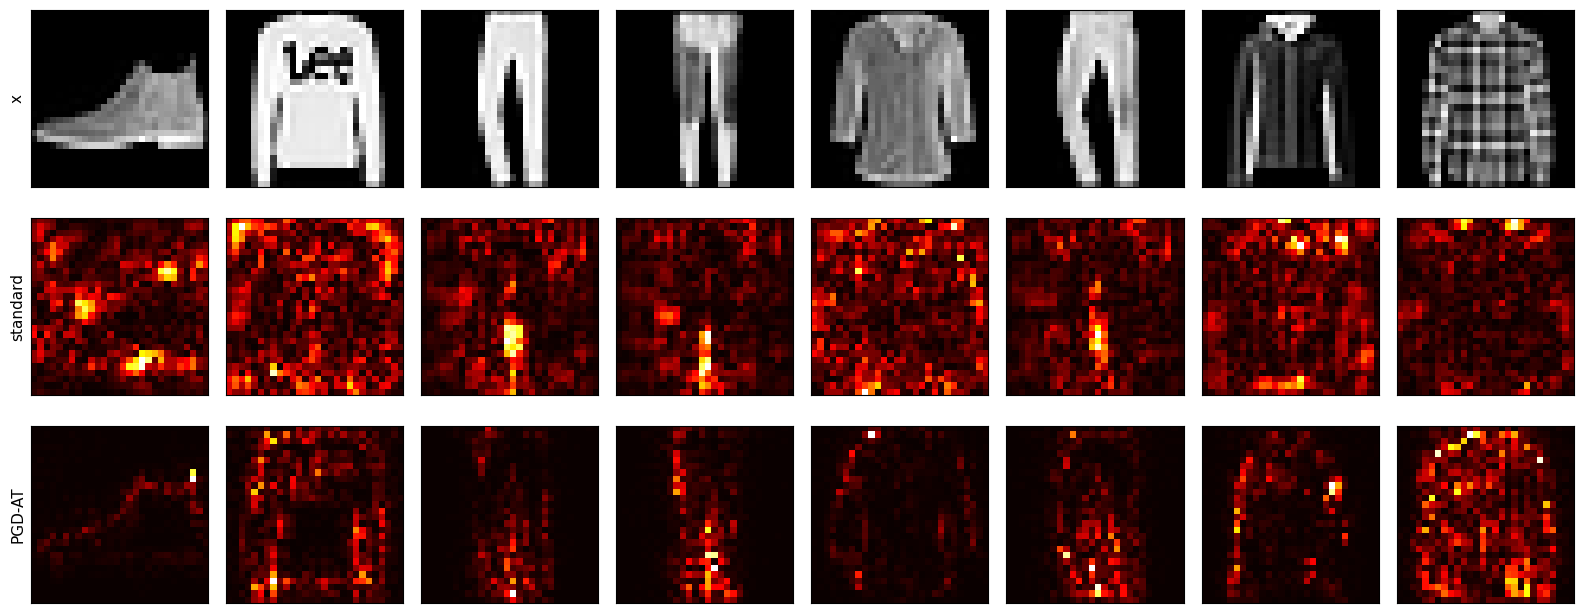

In [67]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** У обычной модели карта шумная и почти равномерно разбросана по всему изображению, включая фон, крупные пятна стоят в случайных местах. У PGD-AT градиент сосредоточен на самом объекте: контуры силуэта, швы, надпись на свитере, клетка на рубашке, а фон почти чёрный, карта напоминает очертания вещи. По числам: фоновых пикселей 49.8%, на них приходится 59.8% массы градиента у обычной модели (даже больше, чем доля фона) и 23.1% у PGD-AT. Это согласуется с разницей PGD accuracy (0.005 против 0.717): обычная модель чувствительна к изменениям фона, которые не несут информации о классе, и атака легко ими пользуется, а робастная модель опирается на признаки самой вещи. Однако одна красивая saliency-карта не доказывает робастность. Это производная в одной точке, первый порядок, а атака ищет худший случай во всём шаре радиуса $\varepsilon$. Модель с gradient masking может давать гладкие "осмысленные" градиенты в самой точке и при этом ломаться на соседних. Кроме того, "интерпретируемость" оценивается на глаз по 8 картинкам. Вывод о робастности можно делать только по сильным атакам (6.2), а карта лишь согласуется с ним.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [68]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [69]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        # grads = torch.autograd.grad(loss, params, create_graph=True); v — список тензоров формы params
        # Hv = d(g^T v)/d(theta): VJP градиента с вектором v, граф градиента сохраняем для следующих вызовов
        return list(torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True))


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [70]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [71]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

initial sharpness: 4.44
eta=0.02  2/eta= 100.0  final loss 0.1494  max sharpness 17.2  last sharpness 17.2
eta=0.05  2/eta=  40.0  final loss 0.1101  max sharpness 42.4  last sharpness 38.2
eta=0.1   2/eta=  20.0  final loss 0.0859  max sharpness 22.4  last sharpness 21.0
eta=0.2   2/eta=  10.0  final loss 0.0691  max sharpness 12.3  last sharpness 11.0


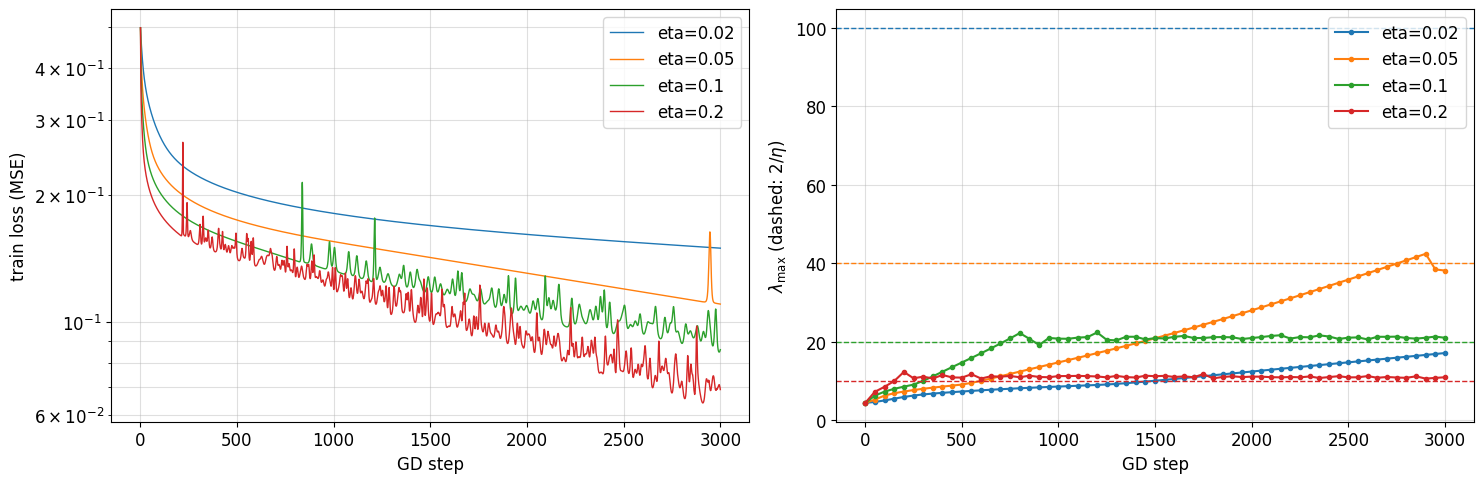

In [72]:
if '7.1' in BONUS_TASKS:
    EOS_EVERY = 50
    # sharpness в начале обучения (одинаковая для всех прогонов, seed 0)
    model0 = make_tanh_mlp(0)
    lam0, _ = top_eigenvalue(lambda: mse_loss(model0), model0.parameters(), iters=30)
    print(f'initial sharpness: {lam0:.2f}')
    EOS_ETAS = [0.02, 0.05, 0.1, 0.2]
    eos = {}
    started = time.perf_counter()
    for eta in EOS_ETAS:
        model = make_tanh_mlp(0)
        params = list(model.parameters())
        optimizer = torch.optim.SGD(params, lr=eta, momentum=0.0)
        losses, sharp_steps, sharpness = [], [], []
        v = None
        for step in range(EOS_STEPS + 1):
            if step % EOS_EVERY == 0:
                lam, v = top_eigenvalue(lambda: mse_loss(model), params, iters=20, v=v)
                sharp_steps.append(step)
                sharpness.append(lam)
            if step == EOS_STEPS:
                break
            loss = mse_loss(model)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
            if not math.isfinite(losses[-1]):
                print(f'eta={eta}: loss diverged at step {step}')
                break
        eos[eta] = dict(loss=losses, steps=sharp_steps, sharpness=sharpness)
        print(f'eta={eta:<5} 2/eta={2 / eta:6.1f}  final loss {losses[-1]:.4f}  '
              f'max sharpness {max(sharpness):.1f}  last sharpness {sharpness[-1]:.1f}')
    RUN_TIMES['bonus_eos_seconds'] = time.perf_counter() - started

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
    for color, (eta, res) in zip(colors, eos.items()):
        ax1.semilogy(range(1, len(res['loss']) + 1), res['loss'], color=color, linewidth=1, label=f'eta={eta}')
        ax2.plot(res['steps'], res['sharpness'], 'o-', color=color, markersize=3, label=f'eta={eta}')
        ax2.axhline(2 / eta, color=color, linestyle='--', linewidth=1)
    ax1.set_ylabel('train loss (MSE)')
    ax2.set_ylabel(r'$\lambda_{\max}$ (dashed: $2/\eta$)')
    for ax in (ax1, ax2):
        ax.set_xlabel('GD step')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.** Начальная sharpness 4.44, для всех $\eta$ в начале $\lambda_{\max} < 2/\eta$. Дальше во всех прогонах идёт progressive sharpening. При $\eta = 0.2$ ($2/\eta = 10$) sharpness дошла до границы примерно к 200-му шагу и дальше держалась около неё (примерно 10.5-12.3, в конце 11.0). При $\eta = 0.1$ ($2/\eta = 20$) граница достигнута примерно на 700-800-м шаге, дальше 20-22.4. При $\eta = 0.05$ ($2/\eta = 40$) sharpness росла почти линейно и дошла до 42.4 только к ~2900-му шагу, после чего опустилась до 38.2. При $\eta = 0.02$ ($2/\eta = 100$) выхода на границу не было: sharpness монотонно выросла до 17.2, это далеко от 100.

Связь с loss: пока $\lambda_{\max} < 2/\eta$, loss падает монотонно (весь прогон $\eta = 0.02$ и почти весь $\eta = 0.05$). В момент выхода на границу на кривой loss появляется резкий всплеск: около шага 220 при $\eta = 0.2$, около 840 при $\eta = 0.1$, около 2940 при $\eta = 0.05$. Сразу после всплеска sharpness перестаёт расти. Дальше loss при $\eta = 0.1$ и $0.2$ немонотонный, с частыми зубцами, но в среднем продолжает убывать: до 0.086 и 0.069 к 3000-му шагу против 0.149 при $\eta = 0.02$. Небольшое превышение $2/\eta$ (на 5-10%) видно на всех трёх прогонах, это и есть поведение edge of stability.

Критерий $\eta < 2/\lambda_{\max}$ выведен для фиксированной квадратичной функции, у которой гессиан не меняется. У сети гессиан зависит от параметров: шаг GD сам меняет кривизну. Когда в направлении верхнего собственного вектора начинается неустойчивость, итерация уходит из этого места в область с меньшей кривизной (self-stabilization), поэтому нет ни расходимости, ни монотонной сходимости, а sharpness колеблется около $2/\eta$. Локальная квадратичная модель верна только на малых расстояниях и не описывает такую нелинейную обратную связь. Ограничение: один seed, 2000 картинок, sharpness по 20 итерациям Lanczos каждые 50 шагов, так что точные моменты выхода на границу определены с точностью до 50 шагов.

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [73]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        if padding:
            x = F.pad(x, (padding, padding, padding, padding))
        B, C_in, H, W = x.shape
        C_out, C_g, kh, kw = weight.shape
        Hf, Wf = H + kh - 1, W + kw - 1 # размер полной линейной свёртки, без цикличности
        Xf = torch.fft.rfft2(x, s=(Hf, Wf)).view(B, groups, C_g, Hf, -1)
        Kf = torch.fft.rfft2(weight.flip(-2, -1), s=(Hf, Wf)).view(groups, C_out // groups, C_g, Hf, -1)
        Yf = torch.einsum('bgchw,gochw->bgohw', Xf, Kf).reshape(B, C_out, Hf, -1)
        y = torch.fft.irfft2(Yf, s=(Hf, Wf))
        y = y[..., kh - 1:H, kw - 1:W][..., ::stride, ::stride] # valid-часть и прореживание
        if bias is not None:
            y = y + bias.view(1, -1, 1, 1)
        return y

In [74]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.** FFT-свёртка честно считает все $(H - k_h + 1)(W - k_w + 1)$ выходов valid-части (и ещё границу полной линейной свёртки размера $(H + k_h - 1)(W + k_w - 1)$), а после прореживания $[::s, ::s]$ остаётся только доля $\approx 1/s^2$. Значит из valid-части выбрасывается $1 - 1/s^2$: 75% при $s = 2$ и 89% при $s = 3$. Прямая свёртка со stride стоит примерно $C_{in} C_{out} k^2 HW / s^2$, а FFT $C_{in} C_{out} HW$ на произведение в частотной области плюс преобразования $O((C_{in} + C_{out} + B C_{in}) HW \log HW)$, не зависящие от $k$. Поэтому FFT всё равно выгоднее, когда $k^2$ заметно больше $s^2$ с учётом константы комплексной арифметики: большие ядра (7x7, 11x11 и больше) при stride 1-2, много каналов (стоимость преобразований делится на $C_{in} C_{out}$ произведений) и большой батч, на котором переиспользуется спектр ядра. Для 3x3 со stride 2 прямой метод всегда выгоднее. Открытый тест прошёл на всех 81 комбинации k, s, p, g.

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [75]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        a, b, c = coeffs
        X = M / (M.norm() + 1e-7)
        transposed = X.shape[0] > X.shape[1]
        if transposed:
            X = X.T
        for _ in range(steps):
            A = X @ X.T
            X = a * X + (b * A + c * (A @ A)) @ X
        return X.T if transposed else X


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    if p.ndim < 2:
                        raise ValueError('ConvMuon supports only parameters with ndim >= 2')
                    g = p.grad
                    state = self.state[p]
                    if 'momentum_buffer' not in state:
                        state['momentum_buffer'] = torch.zeros_like(g)
                    buf = state['momentum_buffer']
                    buf.lerp_(g, 1 - mu)                          # B = mu B + (1 - mu) G
                    update = g.lerp(buf, mu)                      # U = (1 - mu) G + mu B (Nesterov)
                    U = update.reshape(update.shape[0], -1)       # (C_out, C_in k k)
                    m, n = U.shape
                    O = newton_schulz(U)
                    p.add_(O.view_as(p), alpha=-group['lr'] * math.sqrt(max(1.0, m / n)))

In [76]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape) # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [77]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02

    def train_cifar_muon(model, epochs, lr_adamw, lr_muon, weight_decay=0.05, batch_size=256, log=True):
        # тот же протокол, что train_cifar, но 4D-веса свёрток обновляет ConvMuon
        model = model.to(device)
        channels_last = device.type == 'cpu'
        if channels_last:
            model = model.to(memory_format=torch.channels_last)

        def transform(x):
            x = normalize(x)
            return x.contiguous(memory_format=torch.channels_last) if channels_last else x

        conv_w = [p for p in model.parameters() if p.ndim == 4]
        decay = [p for p in model.parameters() if p.ndim in (2, 3)]
        no_decay = [p for p in model.parameters() if p.ndim <= 1]
        muon = ConvMuon(conv_w, lr=lr_muon)
        adamw = MyAdamW([dict(params=decay, weight_decay=weight_decay),
                         dict(params=no_decay, weight_decay=0.0)], lr=lr_adamw)
        total_steps = epochs * math.ceil(len(X_train) / batch_size)
        schedulers = [torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, total_steps, 0.0))
                      for opt in (muon, adamw)]
        history = dict(train_loss=[], test_acc=[])
        start = time.time()
        for epoch in range(epochs):
            model.train()
            loss_sum, n_seen = 0.0, 0
            for x, y in iterate_batches(X_train, Y_train, batch_size, shuffle=True, transform=transform):
                loss = F.cross_entropy(model(x), y)
                muon.zero_grad(set_to_none=True)
                adamw.zero_grad(set_to_none=True)
                loss.backward()
                muon.step()
                adamw.step()
                for s in schedulers:
                    s.step()
                loss_sum += loss.item() * len(y)
                n_seen += len(y)
            history['train_loss'].append(loss_sum / n_seen)
            history['test_acc'].append(accuracy(predict_logits(model, X_test, transform=transform), Y_test))
            if log:
                print(f'epoch {epoch + 1:>2}/{epochs}  train loss {history["train_loss"][-1]:.4f}  '
                      f'test acc {history["test_acc"][-1]:.4f}  {(time.time() - start) / 60:.1f} min')
        model.eval()
        return history

    set_seed(0)
    resnet20_muon = ResNetCIFAR(20)
    started = time.perf_counter()
    hist_muon = train_cifar_muon(resnet20_muon, EPOCHS, LR, MUON_LR)
    RUN_TIMES['bonus_muon_seconds'] = time.perf_counter() - started
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

epoch  1/20  train loss 1.1592  test acc 0.6451  0.3 min
epoch  2/20  train loss 0.6693  test acc 0.7329  0.6 min
epoch  3/20  train loss 0.5049  test acc 0.7418  0.9 min
epoch  4/20  train loss 0.3973  test acc 0.8065  1.2 min
epoch  5/20  train loss 0.3145  test acc 0.8111  1.5 min
epoch  6/20  train loss 0.2435  test acc 0.7926  1.8 min
epoch  7/20  train loss 0.1777  test acc 0.8098  2.1 min
epoch  8/20  train loss 0.1263  test acc 0.8335  2.4 min
epoch  9/20  train loss 0.0894  test acc 0.8295  2.7 min
epoch 10/20  train loss 0.0613  test acc 0.8302  3.0 min
epoch 11/20  train loss 0.0408  test acc 0.8397  3.3 min
epoch 12/20  train loss 0.0254  test acc 0.8401  3.6 min
epoch 13/20  train loss 0.0172  test acc 0.8467  3.9 min
epoch 14/20  train loss 0.0101  test acc 0.8424  4.2 min
epoch 15/20  train loss 0.0058  test acc 0.8425  4.5 min
epoch 16/20  train loss 0.0033  test acc 0.8456  4.8 min
epoch 17/20  train loss 0.0018  test acc 0.8478  5.1 min
epoch 18/20  train loss 0.0011 

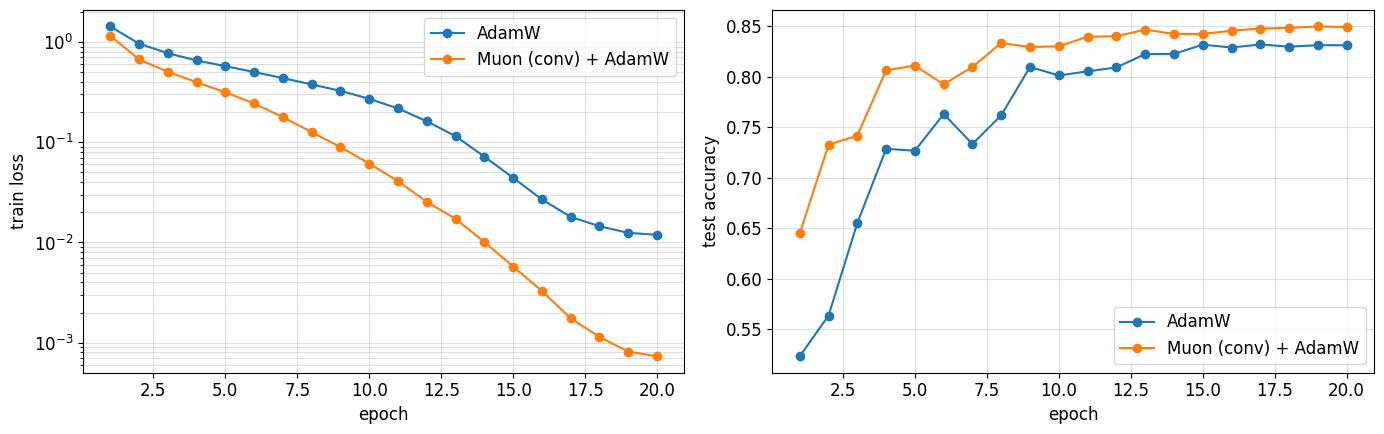

In [78]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.** Train loss быстрее снижает Muon: после 1-й эпохи 1.16 против 1.43 у AdamW, после 5-й 0.31 против 0.57, после 10-й 0.061 против 0.271, в конце 0.0007 против 0.012. Test accuracy при том же бюджете (20 эпох, seed 0) тоже лучше у Muon: 0.849 против 0.831, и Muon впереди AdamW на каждой эпохе (например, 0.807 на 4-й эпохе против 0.729). По времени разница небольшая: 6.1 и 5.7 минуты, итерации Ньютона-Шульца на таких маленьких матрицах (до 64 x 576) стоят мало. Ограничения: это сравнение двух рецептов, а не оптимизаторов в чистом виде (у Muon нет weight decay на свёрточных весах, learning rate не подбирался ни для одного), один seed и одна модель, так что разница 1.8 п.п. не является общим рейтингом.

Память состояния: AdamW хранит два тензора размера параметра ($m$ и $v$), то есть 2 числа на параметр (плюс счётчик шагов). ConvMuon хранит только momentum buffer, 1 число на параметр, а временные матрицы Ньютона-Шульца живут только внутри шага. В нашем ResNet-20 через Muon идут 270 256 из 272 474 параметров (99.2%), так что состояние оптимизатора почти вдвое меньше, чем у чистого AdamW.

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [79]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [80]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.922, 'L0, k=5': 0.644}
standard    0.922  0.894  0.848  0.774  0.644  0.396  0.130  0.026
PGD-AT      0.854  0.818  0.784  0.758  0.722  0.634  0.412  0.286


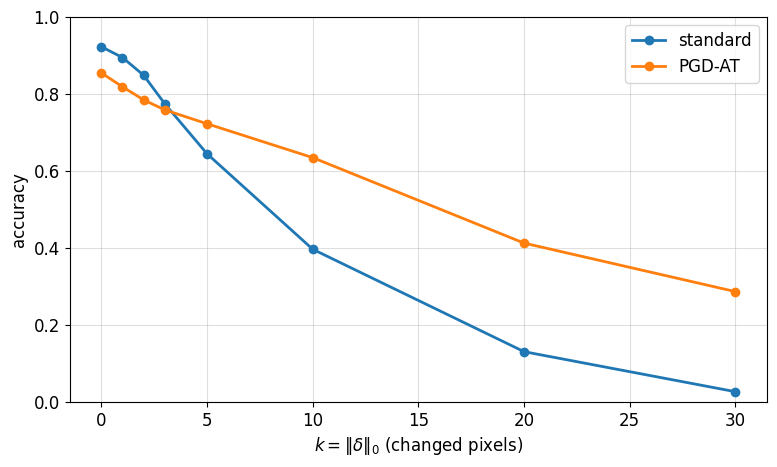

In [81]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.** Частично помогает, но не защищает. Accuracy при k = 0, 1, 2, 3, 5, 10, 20, 30 изменённых пикселях: обычная модель 0.922, 0.894, 0.848, 0.774, 0.644, 0.396, 0.130, 0.026; PGD-AT 0.854, 0.818, 0.784, 0.758, 0.722, 0.634, 0.412, 0.286. При малых k обычная модель ещё выше за счёт более высокой clean accuracy, но начиная с k = 5 робастная модель выше по абсолютной accuracy: при k = 5 она теряет 13 п.п. против 28 п.п. у обычной, при k = 30 остаётся 0.286 против 0.026. Но и её accuracy при 30 пикселях (3.8% картинки) падает до 0.29, то есть $L_\infty$-обучение не даёт устойчивости к $L_0$-атаке. К тому же жадная линеаризованная атака слабая, и найденная accuracy только верхняя оценка.

$L_\infty$-шар радиуса $\varepsilon = 0.1$ разрешает менять каждый пиксель не больше чем на 0.1, а изменение одного пикселя с 0 до 1 имеет $L_\infty$-норму 1, в 10 раз больше $\varepsilon$. Такие возмущения не лежат в шаре, на котором шло обучение, и модель их не видела. PGD-AT по сути уменьшает отклик на маленькие изменения сразу всех пикселей (в линейном приближении это $\varepsilon \|\nabla_x L\|_1$), что заодно немного уменьшает градиент по каждому пикселю и объясняет частичную пользу. Но отклик на большое изменение одного пикселя в нелинейной сети этим не ограничен.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [82]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

FGSM
epoch 1/5  clean 0.728  FGSM 0.596  PGD-20 0.028  0.0 min
epoch 2/5  clean 0.553  FGSM 0.915  PGD-20 0.001  0.1 min
epoch 3/5  clean 0.433  FGSM 0.967  PGD-20 0.001  0.1 min
epoch 4/5  clean 0.339  FGSM 0.971  PGD-20 0.001  0.2 min
epoch 5/5  clean 0.293  FGSM 0.990  PGD-20 0.001  0.2 min
FGSM-RS
epoch 1/5  clean 0.768  FGSM 0.626  PGD-20 0.369  0.0 min
epoch 2/5  clean 0.790  FGSM 0.645  PGD-20 0.398  0.1 min
epoch 3/5  clean 0.793  FGSM 0.715  PGD-20 0.421  0.1 min
epoch 4/5  clean 0.803  FGSM 0.703  PGD-20 0.429  0.2 min
epoch 5/5  clean 0.809  FGSM 0.743  PGD-20 0.356  0.2 min


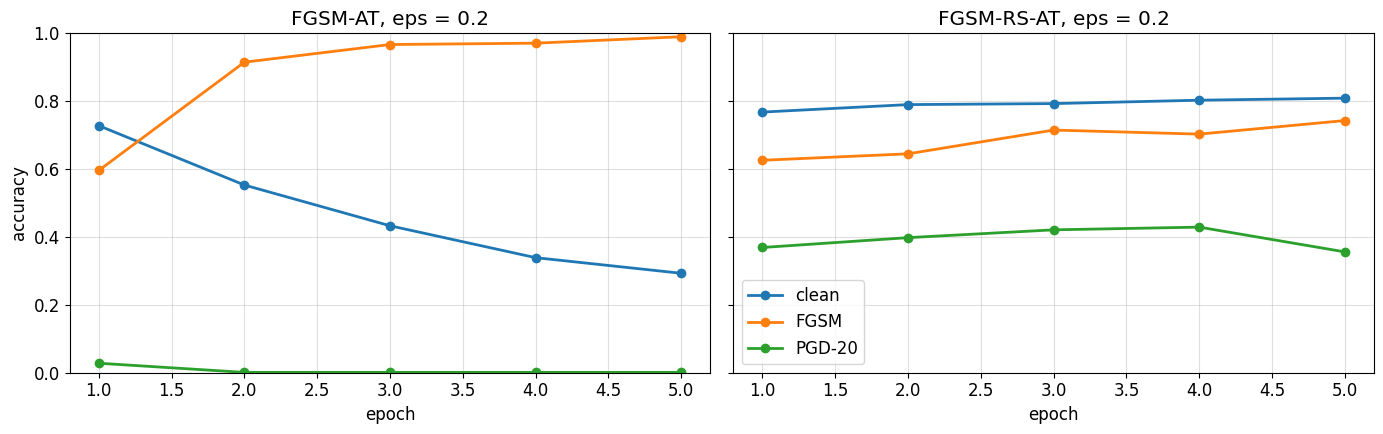

In [83]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [84]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

{'FGSM': {'fgsm': 0.265625, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.73046875, 'pgd20': 0.3515625, 'pgd100_x5': 0.29296875, 'eps_1': 0.0}}


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.** Да, у FGSM-AT с $\varepsilon = 0.2$ резкий спад был. Уже после 1-й эпохи PGD-20 accuracy всего 0.028 (у FGSM-RS в тот же момент 0.369), а со 2-й эпохи 0.001. Одновременно FGSM accuracy растёт: 0.596, 0.915, 0.967, 0.971, 0.990, то есть становится намного выше clean accuracy, которая падает с 0.728 до 0.293. Это классическая картина catastrophic overfitting: модель научилась делать так, что одношаговое FGSM-возмущение перестаёт быть вредным (оно скорее "помогает" классификации), но многошаговая атака ломает её полностью. Поскольку оценка делается раз в эпоху, момент можно указать только с точностью до эпохи: основной обвал произошёл в течение 1-й эпохи и завершился ко 2-й.

Random start картину заметно смягчил, но, похоже, не полностью. У FGSM-RS PGD-20 accuracy первые четыре эпохи растёт (0.369, 0.398, 0.421, 0.429), clean тоже растёт до 0.809. Но на 5-й эпохе PGD-20 падает до 0.356 (минус 7.3 п.п., это больше шума на 1000 объектах), а FGSM accuracy в это же время растёт с 0.703 до 0.743. Метрики начинают расходиться в разные стороны, это похоже на начало того же эффекта, только медленнее, чем без random start.

Усиленная атака на 256 объектах это подтверждает. Для FGSM-AT: FGSM 0.266, PGD-20 0, PGD-100x5 0, $\varepsilon = 1$: 0. FGSM accuracy здесь 0.266, а не 0.990, потому что clean-ошибки считаются ошибками и она ограничена clean accuracy около 0.29; среди правильно классифицированных FGSM почти ничего не ломает. Огромный разрыв между FGSM и PGD и есть признак gradient masking, при этом формально модель проходит проверки из 6.2 (accuracy падает с усилением атаки, при $\varepsilon = 1$ ноль), что хорошо иллюстрирует недостаточность этих проверок. Для FGSM-RS: 0.730, 0.352, 0.293, 0. Здесь PGD-100x5 ниже PGD-20 на 5.9 п.п. (для PGD-AT в 6.2 разница была 0.4 п.п.), так что при $\varepsilon = 0.2$ двадцати шагов уже не хватает и реальная робастность FGSM-RS около 0.29 или ниже. Проверяемая гипотеза: catastrophic overfitting у FGSM-RS зависит от размера шага $\alpha = 1.25\varepsilon$; если повторить обучение с $\alpha = \varepsilon$ (или с более длинным обучением при текущем $\alpha$), спад PGD должен соответственно исчезнуть (или стать резче), как описывают Wong et al. Ограничение: один seed и одна величина $\varepsilon$.